# Train an IQP circuit with Pauli propagation

A small **six-qubit** example using the repository's functions: train a classical Pauli-propagation surrogate against the supplied TFIM ground-state distribution, then evaluate the trained parameters on the exact IQP circuit.

From the repository root, install the training dependencies and open this notebook with the same Python environment:

```sh
python -m pip install -r requirements-training.txt jupyterlab
python -m jupyter lab tutorial_iqp_pauli_propagation.ipynb
```

Run the cells in order. The first training call includes JAX compilation; this example is a tutorial, not a full paper experiment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from train import run
from born.common import supports
from born.models import fourier_matrix, iqp_gates, iqp_surrogate, loss_function

## 1. Configure and train

The IQP circuit is a Hadamard layer, commuting $Z$ rotations, and a final Hadamard layer. Here `depth=12` means **12 rotation gates**, including the six single-qubit gates.

Two cutoffs have different roles:
- `order` is the largest correlator support size retained in the Fourier reconstruction. We keep all orders here (`order=6`).
- `max_flips` truncates the Pauli-propagation expansion of each correlator. We retain terms with at most two flips.

`run` builds the surrogate, differentiates its loss with JAX, trains with Adam, and evaluates exact circuit deployment after training. We use squared Euclidean loss to keep the example simple.

In [2]:
config = {
    "target": "1d_ising",
    "ansatz": "iqp",
    "depth": 12,
    "order": 6,
    "max_flips": 2,
    "iterations": 100,
    "learning_rate": 0.1,
    "seed": 0,
    "loss": "sqe",
    "sigma": 1e-3,          # Only used when loss="mmd".
    "layers": 6,            # Only used by the strongly-entangling ansatz.
    "bond_dim": None,       # No tensor-network surrogate in this example.
    "random_subset": False,
    "anova_degree": None,
}
result = run(config)
print(f"Trained {result['angles'].size} angles for {len(result['history'])} steps.")

Trained 12 angles for 100 steps.


## 2. Call the surrogate directly

These are the same functions used inside `run`. The gate seed reconstructs the circuit supports; `iqp_surrogate` returns a callable that evaluates the retained correlators at any parameter vector. `fourier_matrix` reconstructs the outcome vector, with identity included as the first correlator.

A truncated surrogate can produce negative entries even though its entries sum to one. We leave them visible; exact circuit probabilities are a separate output.

In [3]:
n = 6
selected = [s for s in supports(n) if len(s) <= config["order"]]
gates = iqp_gates(n, config["depth"], config["seed"])
surrogate = iqp_surrogate(n, gates, selected, config["max_flips"])
correlators = np.asarray(surrogate(result["angles"]))
p_surrogate = fourier_matrix(n, selected) @ correlators / 2**n

np.testing.assert_allclose(p_surrogate, result["probabilities"], atol=1e-12)
print(f"Surrogate sum: {p_surrogate.sum():.6f}; minimum entry: {p_surrogate.min():.6f}")

Surrogate sum: 1.000000; minimum entry: 0.000078


## 3. Compare classical training and exact deployment

Use the **same trained angles** for both evaluations. A small surrogate loss does not guarantee a small deployed loss. The training history records losses **before** each parameter update; the values below evaluate the final parameters after all updates.

In [4]:
target = result["target"]
p_deployed = result["deployed_probabilities"]
objective = loss_function(config["loss"], n, sigma=config["sigma"])

print(f"Initial surrogate loss: {result['history'][0]:.6f}")
print(f"Final surrogate loss:   {float(objective(p_surrogate, target)):.6f}")
print(f"Final deployed loss:    {float(objective(p_deployed, target)):.6f}")

Initial surrogate loss: 0.491341
Final surrogate loss:   0.015439
Final deployed loss:    0.015435


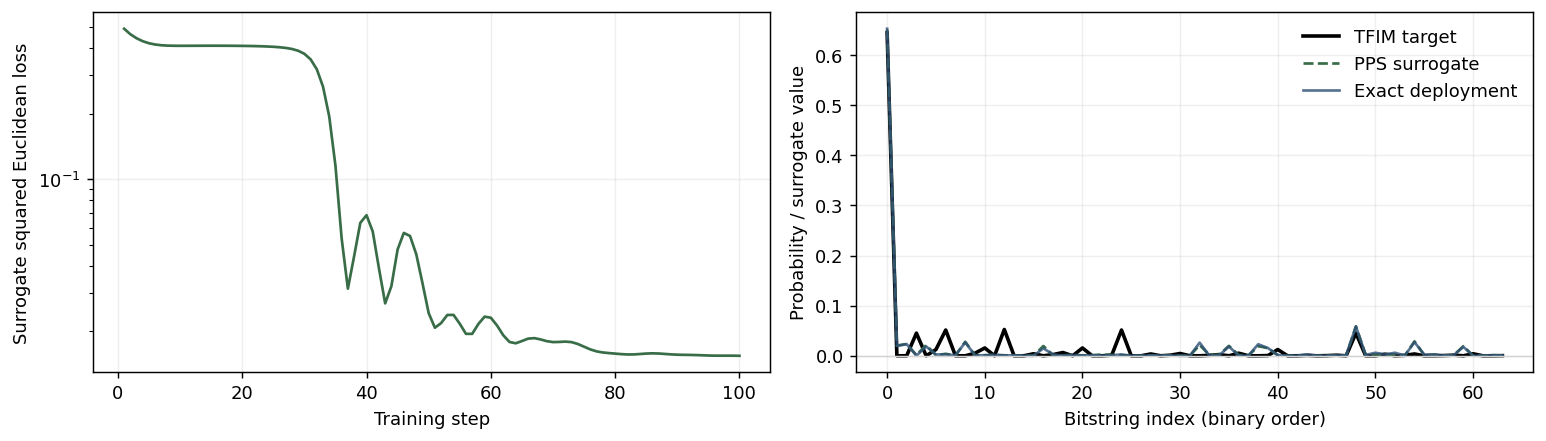

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].semilogy(np.arange(1, len(result["history"]) + 1), result["history"], color="#386d48")
axes[0].set(xlabel="Training step", ylabel="Surrogate squared Euclidean loss")

x = np.arange(2**n)
axes[1].plot(x, target, label="TFIM target", color="black", linewidth=2)
axes[1].plot(x, p_surrogate, label="PPS surrogate", color="#386d48", linestyle="--")
axes[1].plot(x, p_deployed, label="Exact deployment", color="#2e5077", alpha=0.8)
axes[1].axhline(0, color="lightgray", linewidth=0.8)
axes[1].set(xlabel="Bitstring index (binary order)", ylabel="Probability / surrogate value")
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Try another cutoff

Change `max_flips` to `4` and rerun from the configuration cell, keeping the seed fixed. Compare the training time and the gap between surrogate and deployed loss. Setting `max_flips=depth` includes the full propagation expansion; with `order=n`, it recovers exact IQP correlators up to floating-point error, but the computation can grow exponentially.

Alternatively, set `order=3` to study Fourier truncation as well. This introduces a separate approximation even if the retained correlators are computed exactly.

For the historical figure conventions and their limitations, see [REPRODUCTION_NOTES.md](REPRODUCTION_NOTES.md).